# Phase 2 — Machine Learning
## Lesson 2.1.4: Training, Validation, and Test Sets

**Series:** AI & ML — Learn • Build • Grow  
**Module:** 2.1 — ML Fundamentals  
**Primary framework:** PyTorch  
**Environment:** Jupyter Notebook · CPU-friendly  
**Previous lesson:** 2.1.3 — Features, Targets, Datasets, and Labels

---

## Why do we split a dataset?

A model can perform very well on the examples it has already learned from. But that does not tell us whether it will make useful predictions for customers it has never seen.

To get a more honest picture, we divide the available labeled examples into three separate groups:

- **Training set:** examples used to calculate the loss and update the model's parameters.
- **Validation set:** examples used during development to compare choices and monitor performance. They do not update the model's parameters.
- **Test set:** examples held aside for the final evaluation after development decisions are complete.

We will continue with the same 180 synthetic customer examples from Lessons 2.1.2 and 2.1.3. Each example has two features (`monthly_visit_score` and `spending_score`) and a target (`customer_segment`).

> **Big idea:** training teaches the model; validation helps us make development decisions; testing gives a final check on data the model and developer have not used to make those decisions.

## Learning objectives

By the end of this notebook, you should be able to:

- explain why one dataset is divided into training, validation, and test sets;
- describe the different job of each set;
- create reproducible, stratified splits for a classification dataset;
- keep feature rows paired with their correct labels;
- check that the splits are separate and cover every example;
- use a PyTorch `DataLoader` for training and evaluation;
- train using the training set, select a checkpoint using validation loss, and evaluate on the test set only at the end.

This lesson introduces the split workflow. We will study overfitting, underfitting, and generalization more deeply in Lesson 2.1.5, then combine the module's ideas into a simple ML pipeline in Lesson 2.1.6.

## 1. Revisit the customer dataset

We keep the same example and synthetic-data recipe as Lesson 2.1.3 so the lesson sequence feels connected.

| Column | Role in this task |
|---|---|
| `customer_id` | Identifier for tracing a row; not a model feature here |
| `monthly_visit_score` | Feature 1 |
| `spending_score` | Feature 2 |
| `customer_segment` | Classification target / label |

The three categories are `Occasional`, `Regular`, and `High-value`. These are teaching labels, not real customer records.

## 2. Import libraries and make the experiment reproducible

We use PyTorch for tensors, dataset wrappers, the model, and training. We use pandas to inspect tables and Matplotlib to create clear visual summaries.

Everything runs on CPU; no NVIDIA GPU is required.

In [1]:
from pathlib import Path
import copy
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from IPython.display import display

SEED = 21
SPLIT_SEED = 2026
TRAIN_LOADER_SEED = 7

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cpu")
CLASS_NAMES = ["Occasional", "Regular", "High-value"]
CLASS_COLORS = {
    "Occasional": "#38BDF8",
    "Regular": "#F59E0B",
    "High-value": "#A78BFA",
}
SPLIT_COLORS = {
    "train": "#38BDF8",
    "validation": "#F59E0B",
    "test": "#10B981",
}

CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "notebooks":
    LESSON_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "lesson_example").is_dir():
    LESSON_DIR = CURRENT_DIR / "lesson_example"
else:
    LESSON_DIR = CURRENT_DIR

OUTPUT_DIR = LESSON_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch version: 2.10.0+cpu
Device: cpu
Output directory: /mnt/data/phase-2-lesson-2.1.4-training-validation-test-sets/lesson_example/outputs


## 3. Recreate the same 180 customer examples

Each row represents one customer. The two numeric columns are input features, and `customer_segment` is the known class label.

We intentionally recreate the same synthetic dataset with the same data seed used in the previous lesson. This means the examples are consistent across the module.

In [2]:
centers = torch.tensor(
    [
        [2.0, 2.0],   # Occasional
        [7.5, 2.7],   # Regular
        [6.2, 7.5],   # High-value
    ],
    dtype=torch.float32,
)

samples_per_group = 60
feature_noise = torch.tensor([0.65, 0.70], dtype=torch.float32)

feature_parts = []
label_parts = []
for class_id, center in enumerate(centers):
    points = center + torch.randn(samples_per_group, 2) * feature_noise
    points = points.clamp(0.0, 10.0)
    feature_parts.append(points)
    label_parts.append(torch.full((samples_per_group,), class_id, dtype=torch.long))

X_raw = torch.cat(feature_parts, dim=0)
y_ids = torch.cat(label_parts, dim=0)
labels_as_names = [CLASS_NAMES[int(class_id)] for class_id in y_ids]

customer_df = pd.DataFrame(
    {
        "customer_id": [f"C{i:03d}" for i in range(1, len(X_raw) + 1)],
        "monthly_visit_score": X_raw[:, 0].numpy(),
        "spending_score": X_raw[:, 1].numpy(),
        "customer_segment": labels_as_names,
    }
)

FEATURE_COLUMNS = ["monthly_visit_score", "spending_score"]
TARGET_COLUMN = "customer_segment"
class_to_id = {name: index for index, name in enumerate(CLASS_NAMES)}

X_tensor = torch.tensor(customer_df[FEATURE_COLUMNS].to_numpy(), dtype=torch.float32)
y_tensor = torch.tensor(
    customer_df[TARGET_COLUMN].map(class_to_id).to_numpy(),
    dtype=torch.long,
)

print(f"Examples: {len(customer_df)}")
print(f"Feature tensor shape: {tuple(X_tensor.shape)}")
print(f"Target tensor shape: {tuple(y_tensor.shape)}")
display(customer_df.head(6).round(2))

Examples: 180
Feature tensor shape: (180, 2)
Target tensor shape: (180,)


,customer_id,monthly_visit_score,spending_score,customer_segment
0,C001,1.84,1.23,Occasional
1,C002,2.10,2.12,Occasional
2,C003,1.38,1.62,Occasional
3,C004,2.78,2.67,Occasional
4,C005,1.28,1.41,Occasional
5,C006,2.00,2.16,Occasional


## 4. Why not use every example for training?

If the model is evaluated on the exact examples it learned from, the result can be overly optimistic. It may have learned details specific to those examples rather than a relationship that works for new customers.

A held-out set gives us examples that are not used to update the model. We use two held-out roles:

- validation: while we are still developing the model;
- test: after the development choices are finished.

The validation set and test set are both held out from gradient updates, but they are **not interchangeable**. Repeatedly choosing a model based on test results would turn the test set into another validation set.

## 5. Understand the three sets

| Set | Main job | Used for gradient updates? | Used when? |
|---|---|---:|---|
| Training | Learn model parameters | Yes | During training |
| Validation | Compare choices and monitor training | No | During development |
| Test | Final evaluation of the chosen model | No | At the end |

A common starting split is **70% training, 15% validation, and 15% test**. These percentages are not a universal rule. The right choice depends on dataset size, task, and project constraints. We use this ratio because our teaching dataset has 180 examples.

## 6. Create stratified train, validation, and test splits

This is a **classification** example. A stratified split tries to preserve the proportion of each class in each set.

Our dataset has 60 examples in each of three classes. With a 70/15/15 split, each class contributes:

- 42 examples to training;
- 9 examples to validation;
- 9 examples to testing.

We split the row indices first, then use those same indices to select both `X` and `y`. This keeps every feature row paired with the correct target.

In [3]:
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15


def stratified_split_indices(
    labels,
    train_ratio=0.70,
    validation_ratio=0.15,
    test_ratio=0.15,
    seed=2026,
):
    """Return reproducible, class-aware indices for train/validation/test."""
    ratios = (train_ratio, validation_ratio, test_ratio)
    if any(ratio <= 0 for ratio in ratios) or not np.isclose(sum(ratios), 1.0):
        raise ValueError("All split ratios must be positive and add up to 1.0.")

    labels = torch.as_tensor(labels, dtype=torch.long)
    generator = torch.Generator().manual_seed(seed)
    collected = {"train": [], "validation": [], "test": []}

    for class_id in torch.unique(labels, sorted=True):
        class_indices = torch.where(labels == class_id)[0]
        shuffled = class_indices[torch.randperm(len(class_indices), generator=generator)]

        n_train = int(round(len(shuffled) * train_ratio))
        n_validation = int(round(len(shuffled) * validation_ratio))

        collected["train"].append(shuffled[:n_train])
        collected["validation"].append(shuffled[n_train:n_train + n_validation])
        collected["test"].append(shuffled[n_train + n_validation:])

    result = {}
    for split_name, chunks in collected.items():
        combined = torch.cat(chunks)
        order = torch.randperm(len(combined), generator=generator)
        result[split_name] = combined[order]

    return result


split_indices = stratified_split_indices(
    y_tensor,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=SPLIT_SEED,
)

for split_name, indices in split_indices.items():
    print(f"{split_name:10s}: {len(indices):3d} examples")

train     : 126 examples
validation:  27 examples
test      :  27 examples


## 7. Check split sizes and class balance

A correct split should satisfy two different checks:

1. The split sizes should match our chosen ratios as closely as whole examples allow.
2. For stratified classification splits, each set should contain the intended class proportions.

These checks do not prove that a model is good. They help us verify that the data partition itself was constructed as intended.

In [4]:
split_labels = {
    split_name: y_tensor[indices]
    for split_name, indices in split_indices.items()
}

split_summary = pd.DataFrame(
    {
        split_name: [int((labels == class_id).sum()) for class_id in range(len(CLASS_NAMES))]
        for split_name, labels in split_labels.items()
    },
    index=CLASS_NAMES,
)
split_summary.index.name = "customer_segment"

display(split_summary)
print("Total examples across splits:", sum(len(v) for v in split_indices.values()))

,train,validation,test
customer_segment,,,
Occasional,42,9,9
Regular,42,9,9
High-value,42,9,9


Total examples across splits: 180


## 8. Confirm that the splits do not overlap

Every example must belong to exactly one split.

- **No overlap:** an index cannot appear in both training and validation, for example.
- **Full coverage:** every original example must appear in one of the three sets.

We check both conditions explicitly rather than assuming that the split function worked correctly.

In [5]:
index_sets = {
    name: set(indices.tolist())
    for name, indices in split_indices.items()
}

assert index_sets["train"].isdisjoint(index_sets["validation"])
assert index_sets["train"].isdisjoint(index_sets["test"])
assert index_sets["validation"].isdisjoint(index_sets["test"])

all_indices = index_sets["train"] | index_sets["validation"] | index_sets["test"]
assert all_indices == set(range(len(customer_df)))

print("No overlapping indices: PASS")
print("Every original example is assigned once: PASS")

No overlapping indices: PASS
Every original example is assigned once: PASS


## 9. Visualize the three partitions

Each panel shows one part of the same feature space. The point colors show the customer class, while the panel title shows which split the customer belongs to.

Notice that the three sets cover the same kinds of customer patterns. The exact points are different because the indices are separate.

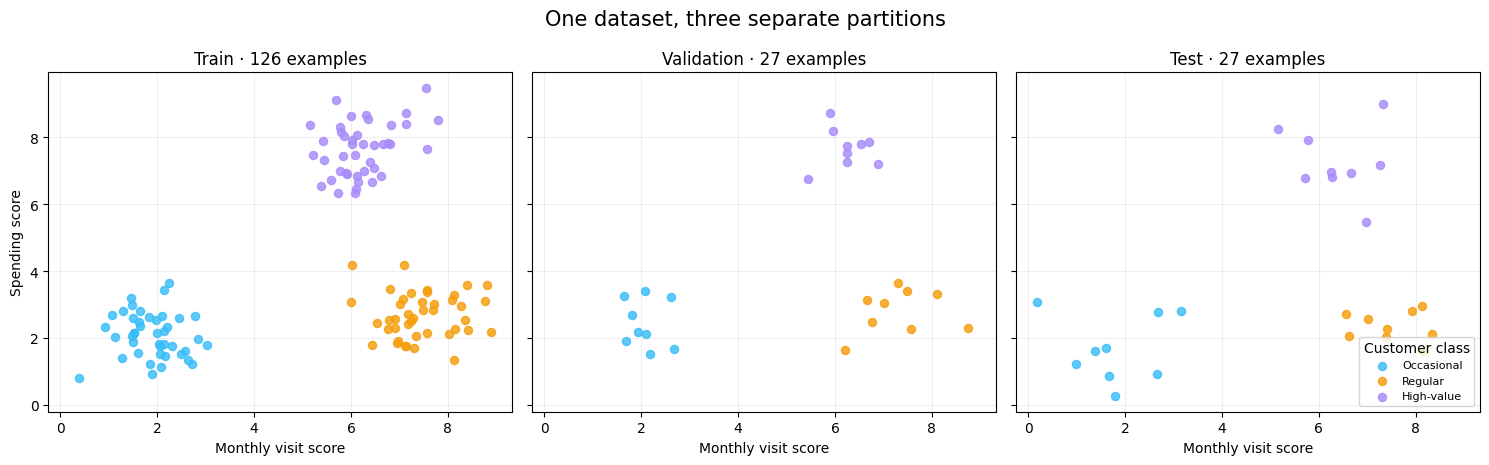

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharex=True, sharey=True)
for ax, split_name in zip(axes, ["train", "validation", "test"]):
    idx = split_indices[split_name]
    points = X_tensor[idx].numpy()
    labels = y_tensor[idx].numpy()
    for class_id, class_name in enumerate(CLASS_NAMES):
        mask = labels == class_id
        ax.scatter(
            points[mask, 0], points[mask, 1],
            s=34, alpha=0.82, color=CLASS_COLORS[class_name], label=class_name,
        )
    ax.set_title(f"{split_name.title()} · {len(idx)} examples")
    ax.set_xlabel("Monthly visit score")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Spending score")
axes[-1].legend(title="Customer class", loc="lower right", fontsize=8)
fig.suptitle("One dataset, three separate partitions", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "three_split_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Compare random splitting with stratified splitting

A plain random split may work, but it can produce different class proportions in each partition—especially when a dataset is small or a class is rare.

Stratification is a useful option for classification when preserving class representation matters. It is not a requirement for every ML task, and it does not fix biased or unrepresentative data.

In [7]:
naive_generator = torch.Generator().manual_seed(31415)
naive_order = torch.randperm(len(y_tensor), generator=naive_generator)
n_train = int(round(len(y_tensor) * TRAIN_RATIO))
n_validation = int(round(len(y_tensor) * VALIDATION_RATIO))
naive_indices = {
    "train": naive_order[:n_train],
    "validation": naive_order[n_train:n_train + n_validation],
    "test": naive_order[n_train + n_validation:],
}

naive_counts = pd.DataFrame(
    {
        split_name: [int((y_tensor[idx] == class_id).sum()) for class_id in range(len(CLASS_NAMES))]
        for split_name, idx in naive_indices.items()
    },
    index=CLASS_NAMES,
)
print("Plain random split class counts:")
display(naive_counts)
print("Stratified split class counts:")
display(split_summary)

Plain random split class counts:


,train,validation,test
Occasional,45,8,7
Regular,43,9,8
High-value,38,10,12


Stratified split class counts:


,train,validation,test
customer_segment,,,
Occasional,42,9,9
Regular,42,9,9
High-value,42,9,9


## 11. Wrap each split in a PyTorch Dataset and DataLoader

`TensorDataset` pairs each feature tensor row with its target. `Subset` selects only the indices belonging to one split. `DataLoader` creates batches from that subset.

We shuffle the **training** examples each epoch. Validation and test loaders are not shuffled; their job is to measure the model consistently, not to update it.

In [8]:
full_dataset = TensorDataset(X_tensor, y_tensor)

train_dataset = Subset(full_dataset, split_indices["train"].tolist())
validation_dataset = Subset(full_dataset, split_indices["validation"].tolist())
test_dataset = Subset(full_dataset, split_indices["test"].tolist())

BATCH_SIZE = 16
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(TRAIN_LOADER_SEED),
)
validation_loader = DataLoader(validation_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

batch_features, batch_targets = next(iter(train_loader))
print("Training batch feature shape:", tuple(batch_features.shape))
print("Training batch target shape:", tuple(batch_targets.shape))
print("One batch keeps each feature row paired with its target.")

Training batch feature shape: (16, 2)
Training batch target shape: (16,)
One batch keeps each feature row paired with its target.


## 12. Train a simple PyTorch classifier using the training set

To make the three roles practical, we train a small linear classifier.

- The training loop receives batches only from `train_loader`.
- The optimizer updates parameters using training loss.
- We measure validation loss and accuracy after each epoch, without gradient updates.

We are not trying to find the most powerful customer classifier. The model is intentionally small so that we can focus on the split workflow.

In [9]:
class CustomerClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.output_layer = nn.Linear(in_features=2, out_features=3)

    def forward(self, features):
        return self.output_layer(features)


torch.manual_seed(7)
model = CustomerClassifier().to(DEVICE)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

print(model)

CustomerClassifier(
  (output_layer): Linear(in_features=2, out_features=3, bias=True)
)


## 13. Write the training and evaluation steps

The training function is allowed to calculate gradients and update parameters. The evaluation function turns gradient tracking off and only measures predictions.

Keeping these functions separate helps us avoid accidentally training on validation or test examples.

In [10]:
def train_one_epoch(model, data_loader, loss_function, optimizer, device):
    model.train()
    total_loss = 0.0
    total_examples = 0

    for features, targets in data_loader:
        features = features.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        logits = model(features)
        loss = loss_function(logits, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(targets)
        total_examples += len(targets)

    return total_loss / total_examples


def evaluate(model, data_loader, loss_function, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total_examples = 0

    with torch.no_grad():
        for features, targets in data_loader:
            features = features.to(device)
            targets = targets.to(device)
            logits = model(features)
            loss = loss_function(logits, targets)

            total_loss += loss.item() * len(targets)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += len(targets)

    return total_loss / total_examples, correct / total_examples

## 14. Train, monitor validation, and keep the best checkpoint

After each training epoch, we measure validation loss. We save a copy of the model parameters whenever validation loss improves.

The validation set influences our development decision—**which checkpoint to keep**—but it does not produce gradients or parameter updates.

Notice what is intentionally missing from this loop: there is no call to `evaluate(model, test_loader, ...)`. We keep the test set out of model development.

In [11]:
EPOCHS = 100
history = []
best_validation_loss = float("inf")
best_epoch = None
best_model_state = None

for epoch in range(1, EPOCHS + 1):
    training_loss = train_one_epoch(
        model, train_loader, loss_function, optimizer, DEVICE
    )
    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, loss_function, DEVICE
    )

    history.append(
        {
            "epoch": epoch,
            "training_loss": training_loss,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
        }
    )

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())

    if epoch in (1, 10, 25, 50, 75, 100):
        print(
            f"Epoch {epoch:3d} | "
            f"train loss: {training_loss:.4f} | "
            f"validation loss: {validation_loss:.4f} | "
            f"validation accuracy: {validation_accuracy:.1%}"
        )

# Restore the checkpoint selected using validation loss.
model.load_state_dict(best_model_state)
print(f"\nBest validation checkpoint: epoch {best_epoch}")
print(f"Best validation loss: {best_validation_loss:.4f}")

Epoch   1 | train loss: 1.3152 | validation loss: 0.8394 | validation accuracy: 66.7%
Epoch  10 | train loss: 0.4377 | validation loss: 0.4199 | validation accuracy: 81.5%
Epoch  25 | train loss: 0.2633 | validation loss: 0.2594 | validation accuracy: 100.0%


Epoch  50 | train loss: 0.1549 | validation loss: 0.1532 | validation accuracy: 100.0%
Epoch  75 | train loss: 0.1091 | validation loss: 0.1077 | validation accuracy: 100.0%


Epoch 100 | train loss: 0.0844 | validation loss: 0.0822 | validation accuracy: 100.0%

Best validation checkpoint: epoch 100
Best validation loss: 0.0822


## 15. Visualize training and validation loss

Training loss shows how well the model fits examples used for parameter updates. Validation loss shows how the current model performs on separate examples during development.

A validation curve is useful evidence when comparing training checkpoints. It is not the final test result.

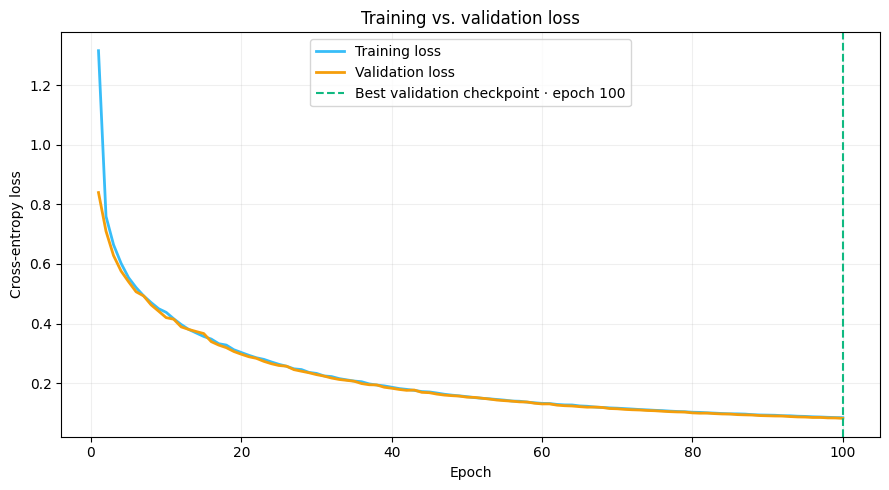

In [12]:
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history_df["epoch"], history_df["training_loss"], label="Training loss", color="#38BDF8", linewidth=2)
ax.plot(history_df["epoch"], history_df["validation_loss"], label="Validation loss", color="#F59E0B", linewidth=2)
ax.axvline(best_epoch, color="#10B981", linestyle="--", label=f"Best validation checkpoint · epoch {best_epoch}")
ax.set_title("Training vs. validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_validation_loss.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. Keep the test set untouched until the final evaluation

Now that we have finished the development choice and restored the checkpoint selected by validation loss, we can evaluate the test set.

The test set is not used to:

- calculate gradients;
- update the model's parameters;
- choose the learning rate or number of epochs;
- select the best checkpoint.

We evaluate it now as a final check. In a real project, repeatedly changing the model after looking at test results would weaken the independence of that test result.

In [13]:
# Final evaluation: this is the first and only test-set evaluation in this notebook.
test_loss, test_accuracy = evaluate(
    model, test_loader, loss_function, DEVICE
)

print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.1%}")

Final test loss: 0.1065
Final test accuracy: 100.0%


## 17. Review the complete split summary

Our split sizes and results describe this one reproducible synthetic experiment. A high score on this simple dataset does not guarantee the same performance on real customer data.

The important learning outcome is the **discipline** of the workflow: train on training data, use validation for development decisions, and reserve test data for final evaluation.

In [14]:
summary_table = pd.DataFrame(
    {
        "purpose": [
            "Fit model parameters",
            "Monitor and choose a checkpoint",
            "Final evaluation",
        ],
        "examples": [
            len(train_dataset),
            len(validation_dataset),
            len(test_dataset),
        ],
        "gradient_updates": ["Yes", "No", "No"],
        "when_used": ["Training", "During development", "At the end"],
    },
    index=["Training", "Validation", "Test"],
)
display(summary_table)

,purpose,examples,gradient_updates,when_used
Training,Fit model parameters,126,Yes,Training
Validation,Monitor and choose a checkpoint,27,No,During development
Test,Final evaluation,27,No,At the end


## 18. Important notes and common mistakes

1. **Do not train on validation or test data.** Their purpose is to provide separate checks.
2. **Do not repeatedly tune against the test set.** Once test results guide development decisions, the test set is no longer an untouched final check.
3. **Keep pairs aligned.** A feature row must stay paired with its correct target after splitting.
4. **Avoid overlap.** An example should not be in two partitions.
5. **Use stratification thoughtfully.** It can preserve class proportions in classification datasets, but it does not make a dataset representative or solve every data-quality problem.
6. **Fit data-dependent preprocessing on training data only.** For example, if a later lesson standardizes features using a mean and standard deviation, calculate those values from the training set and apply them to validation/test. Do not let held-out data influence the fitted preprocessing.
7. **Ratios are choices, not laws.** 70/15/15 is an illustrative split for this dataset, not a universal prescription.

We will study generalization and common evaluation traps in the next lessons.

## 19. Knowledge check and coding challenges

Answer in your own words:

1. What is the training set allowed to do that the validation and test sets are not?
2. Why do we use validation data while developing a model?
3. Why should the test set be evaluated only after model-development decisions are complete?
4. What does stratification try to preserve in this classification example?
5. Why must the feature rows and target labels be split with the same indices?
6. Does a 70/15/15 split have to be used for every ML project? Explain.

### Coding challenge A — Change the split ratios

Try 60% training, 20% validation, and 20% testing. Re-run the split cells and compare the class counts. Keep the test set out of the training and checkpoint-selection loops.

### Coding challenge B — Compare stratified and plain random splitting

Use a different seed for the plain random split. Compare the class proportions. Explain why class balance can matter when the dataset is small or classes are uneven.

### Coding challenge C — Trace one example

Choose one `customer_id`. Find its split assignment and verify that its two feature values remain paired with the correct `customer_segment`.

---

## Recap

- **Training:** learn model parameters.
- **Validation:** guide development decisions.
- **Test:** provide a final evaluation of the chosen model.

**Next lesson:** 2.1.5 — Overfitting, Underfitting, and Generalization.

## 20. Export reproducible artifacts for the video-generation project

The notebook is the source of truth for split counts, sample rows, loss history, checkpoint selection, and the final test result. Manim scenes read these exported files rather than creating a separate dataset or training another model.

In [15]:
# Save the original dataset and its split assignment for animation and review.
split_by_index = {}
for split_name, indices in split_indices.items():
    for index in indices.tolist():
        split_by_index[index] = split_name

export_df = customer_df.copy()
export_df["split"] = [split_by_index[i] for i in range(len(export_df))]
export_df.to_csv(OUTPUT_DIR / "customer_split_assignments.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
customer_df.to_csv(OUTPUT_DIR / "customer_dataset.csv", index=False)

# Class counts for both naive and stratified splits.
stratified_counts = {
    split_name: {
        CLASS_NAMES[class_id]: int((y_tensor[indices] == class_id).sum())
        for class_id in range(len(CLASS_NAMES))
    }
    for split_name, indices in split_indices.items()
}
naive_class_counts = {
    split_name: {
        CLASS_NAMES[class_id]: int((y_tensor[indices] == class_id).sum())
        for class_id in range(len(CLASS_NAMES))
    }
    for split_name, indices in naive_indices.items()
}

results = {
    "lesson": "2.1.4",
    "title": "Training, Validation, and Test Sets",
    "data_seed": SEED,
    "split_seed": SPLIT_SEED,
    "train_loader_seed": TRAIN_LOADER_SEED,
    "device": str(DEVICE),
    "number_of_examples": int(len(customer_df)),
    "feature_columns": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "class_names": CLASS_NAMES,
    "split_ratios": {"train": TRAIN_RATIO, "validation": VALIDATION_RATIO, "test": TEST_RATIO},
    "split_sizes": {name: int(len(indices)) for name, indices in split_indices.items()},
    "stratified_class_counts": stratified_counts,
    "naive_random_class_counts": naive_class_counts,
    "no_overlap": True,
    "full_coverage": True,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_validation_loss),
    "best_validation_accuracy": float(history_df.loc[history_df["epoch"] == best_epoch, "validation_accuracy"].iloc[0]),
    "final_test_loss": float(test_loss),
    "final_test_accuracy": float(test_accuracy),
    "first_examples": customer_df.head(5).round(3).to_dict(orient="records"),
}
(OUTPUT_DIR / "lesson_results.json").write_text(
    json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Exported dataset, split assignments, training history, and lesson_results.json")

Exported dataset, split assignments, training history, and lesson_results.json


## 21. Export a visual summary of the split sizes

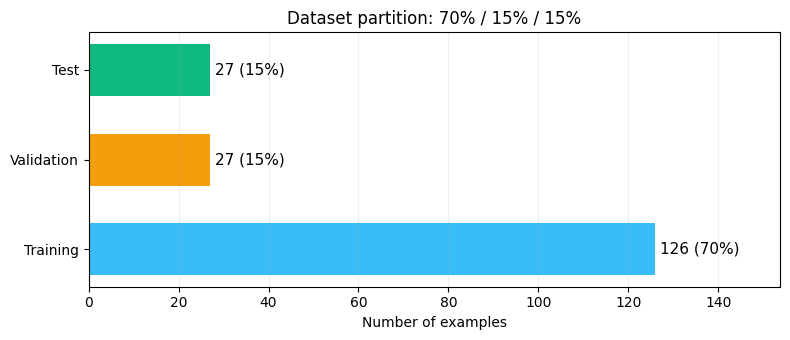

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
labels = ["Training", "Validation", "Test"]
values = [len(train_dataset), len(validation_dataset), len(test_dataset)]
colors = [SPLIT_COLORS["train"], SPLIT_COLORS["validation"], SPLIT_COLORS["test"]]
bars = ax.barh(labels, values, color=colors, height=0.58)
for bar, value in zip(bars, values):
    ax.text(value + 1, bar.get_y() + bar.get_height()/2, f"{value} ({value/len(customer_df):.0%})", va="center", fontsize=11)
ax.set_xlim(0, max(values) * 1.22)
ax.set_title("Dataset partition: 70% / 15% / 15%")
ax.set_xlabel("Number of examples")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "split_sizes.png", dpi=160, bbox_inches="tight")
plt.show()

## 22. Export a class-distribution comparison

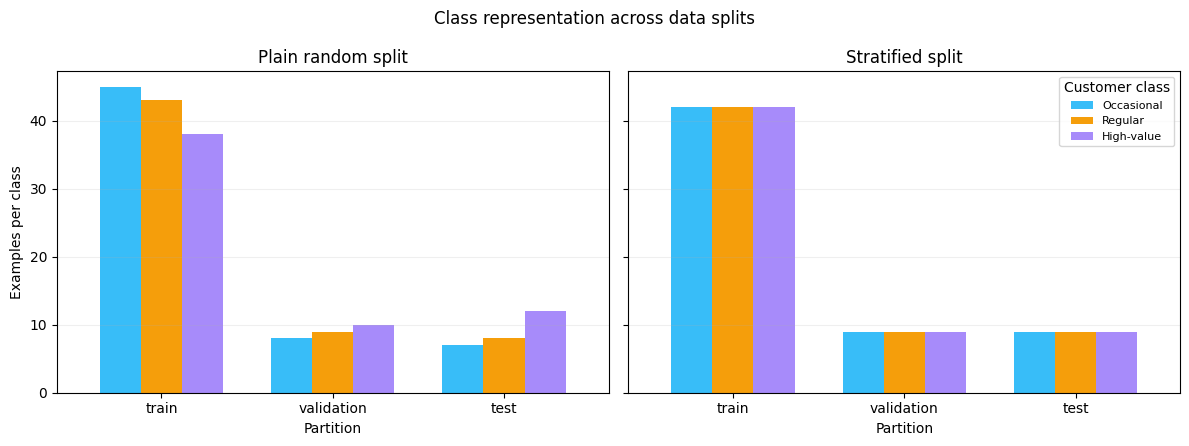

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, count_df, title in [
    (axes[0], naive_counts, "Plain random split"),
    (axes[1], split_summary, "Stratified split"),
]:
    count_df.T.plot(kind="bar", ax=ax, color=[CLASS_COLORS[name] for name in CLASS_NAMES], width=0.72)
    ax.set_title(title)
    ax.set_xlabel("Partition")
    ax.set_ylabel("Examples per class")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)
axes[1].legend(title="Customer class", fontsize=8)
axes[0].get_legend().remove()
fig.suptitle("Class representation across data splits")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution_comparison.png", dpi=160, bbox_inches="tight")
plt.show()